# Week 7-C: Retrieval-Aware Semantic Sufficiency Allocation

## 1. Scientific Motivation & The W7-B Failure Diagnosis

In **Week 7-B**, we established two critical findings:
1. Under **semantic passage routing**, the per-query quality-vs-budget response surface changes dramatically compared to lexical BM25 prefix routing:
   - For **49.8% of DEV queries**, the $\epsilon$-optimal representation budget shifts.
   - The semantic $\epsilon$-oracle achieves **$F_1 = 0.4869$** at mean $k = 3.30$ and context = 775.2 tokens (55.38% context reduction vs static $k=8$).
2. However, retraining an adaptive budget allocator using the **old W4 5-feature representation** achieved only **$F_1 = 0.3522$** at mean $k = 3.48$.
   - Average predicted budget ($k = 3.48$) was remarkably close to oracle mean $k$ ($3.30$), proving that global budget calibration was not the problem.
   - The allocator was assigning the **wrong budget to the wrong query** because the old 5 features (designed for BM25 prefixing) were blind to semantic routing dynamics.

### The W7-C Formulation: Candidate-Level Sufficiency Prediction
Instead of treating budget allocation as a brittle multiclass label prediction $q \rightarrow k$, W7-C formulates budget selection as **candidate-level representation sufficiency prediction**:
$$\boxed{(q, D_{1:10}, k) \longrightarrow \text{sufficiency probability } P(z(q,k)=1) \text{ and continuous regret } \hat{r}(q,k)}$$

For candidate budgets $K = \{2, 4, 5, 6, 8\}$:
- Regret: $r(q,k) = \max_{k'} F_1(q, k') - F_1(q,k)$
- Sufficiency target: $z(q,k) = \mathbf{1}[r(q,k) \le \epsilon]$ with $\epsilon = 0.01$
- Decision rule: $\hat{k} = \min \{ k \in K : P_k \ge \tau \}$, fallback $k=8$.


## Section 1: Setup, Environment, and Reproducibility


In [1]:
import os
import sys
import json
import time
import yaml
from pathlib import Path
from typing import Dict, List, Any, Tuple

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

# Resolve Project Root across execution environments
_curr = Path.cwd().resolve()
candidates = [_curr, _curr.parent, _curr.parent.parent]
PROJECT_ROOT = next((p for p in candidates if (p / "src").is_dir() and (p / "configs").is_dir()), _curr)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

SARA_ROOT = PROJECT_ROOT / "Baselines/SARA-main"
if str(SARA_ROOT) not in sys.path:
    sys.path.append(str(SARA_ROOT))

# Load Week 7-C Configuration
CONFIG_PATH = PROJECT_ROOT / "configs/week7/w7c_retrieval_aware_allocator.yaml"
with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

# Set random seeds
SEED = cfg.get("seed", 42)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
BUDGETS = cfg.get("budgets", [2, 4, 5, 6, 8])
EPSILON = cfg.get("epsilon", 0.01)

# Ensure output directories exist
for p_key in ["features_dir", "models_dir", "tables_dir", "figures_dir", "bootstrap_dir", "diagnostics_dir", "smoke_dir", "logs_dir"]:
    Path(cfg["paths"][p_key]).mkdir(parents=True, exist_ok=True)

print(f"Project Root: {PROJECT_ROOT}")
print(f"Device: {DEVICE} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")
print(f"Deployable Budgets: {BUDGETS}, Epsilon: {EPSILON}")


Project Root: /home/gunavenkat/Downloads/CS787-RAG-Project
Device: cuda (NVIDIA TITAN RTX)
Deployable Budgets: [2, 4, 5, 6, 8], Epsilon: 0.01


## Section 2: Split Integrity & TEST Split Inaccessibility Guard


In [2]:
from src.week7.w7c.data import assert_test_disabled, load_w7c_fit_val_splits, load_w7c_dataset_bundle

# 1. Assert TEST split is strictly disabled
try:
    assert_test_disabled("test")
except RuntimeError as e:
    print(f"PASS: TEST split access guard strictly validated: {e}")

# 2. Load TRAIN and DEV dataset bundles
print("\nLoading dataset bundles...")
train_bundle = load_w7c_dataset_bundle(cfg["paths"]["train_retrieval"], split="train")
dev_bundle = load_w7c_dataset_bundle(cfg["paths"]["dev_retrieval"], split="dev")

print(f"  TRAIN Queries: {train_bundle['n_queries']} across {train_bundle['n_papers']} papers")
print(f"  DEV Queries:   {dev_bundle['n_queries']} across {dev_bundle['n_papers']} papers")

# Assert zero leakage
train_q_set = set(train_bundle["question_ids"])
dev_q_set = set(dev_bundle["question_ids"])
assert train_q_set.isdisjoint(dev_q_set), "LEAKAGE: Overlap between TRAIN and DEV question IDs!"

# 3. Load TRAIN-FIT and INTERNAL-VAL split manifests
df_fit_manifest, df_val_manifest = load_w7c_fit_val_splits(
    train_fit_manifest_path=cfg["paths"]["train_fit_manifest"],
    internal_val_manifest_path=cfg["paths"]["internal_val_manifest"],
)
print(f"  TRAIN-FIT:     {len(df_fit_manifest)} queries ({df_fit_manifest['paper_id'].nunique()} papers)")
print(f"  INTERNAL-VAL:  {len(df_val_manifest)} queries ({df_val_manifest['paper_id'].nunique()} papers)")


PASS: TEST split access guard strictly validated: TEST split access is strictly prohibited in Week 7-C! TEST must remain untouched.

Loading dataset bundles...
  TRAIN Queries: 2088 across 772 papers
  DEV Queries:   231 across 86 papers
  TRAIN-FIT:     1746 queries (656 papers)
  INTERNAL-VAL:  342 queries (116 papers)


## Section 3: Load Response Surfaces & Build Candidate-Budget Datasets


In [3]:
from src.week7.w7c.data import build_candidate_budget_dataframe

# Load canonical W7-B response surfaces
df_train_matrix = pd.read_csv(cfg["paths"]["train_semantic_matrix"])
df_train_matrix["question_id"] = df_train_matrix["question_id"].astype(str).str.strip()
df_train_matrix["paper_id"] = df_train_matrix["paper_id"].astype(str).str.strip()

df_dev_matrix = pd.read_csv(cfg["paths"]["dev_semantic_matrix"])
df_dev_matrix["question_id"] = df_dev_matrix["question_id"].astype(str).str.strip()
df_dev_matrix["paper_id"] = df_dev_matrix["paper_id"].astype(str).str.strip()

print(f"Loaded TRAIN response matrix: {df_train_matrix.shape} (2088 queries x 5 budgets)")
print(f"Loaded DEV response matrix:   {df_dev_matrix.shape} (231 queries x 5 budgets)")

# Filter into paper-disjoint TRAIN-FIT and INTERNAL-VAL matrices
fit_qids_set = set(df_fit_manifest["question_id"])
val_qids_set = set(df_val_manifest["question_id"])

df_fit_matrix = df_train_matrix[df_train_matrix["question_id"].isin(fit_qids_set)].copy().reset_index(drop=True)
df_val_matrix = df_train_matrix[df_train_matrix["question_id"].isin(val_qids_set)].copy().reset_index(drop=True)

print(f"TRAIN-FIT Matrix:    {df_fit_matrix.shape}")
print(f"INTERNAL-VAL Matrix: {df_val_matrix.shape}")

# Expand into candidate-budget pairs (q, k)
df_fit_cand = build_candidate_budget_dataframe(df_fit_matrix, budgets=BUDGETS, epsilon=EPSILON, split_name="train_fit")
df_val_cand = build_candidate_budget_dataframe(df_val_matrix, budgets=BUDGETS, epsilon=EPSILON, split_name="internal_val")
df_dev_cand = build_candidate_budget_dataframe(df_dev_matrix, budgets=BUDGETS, epsilon=EPSILON, split_name="dev")

print(f"\nCandidate rows expanded:")
print(f"  TRAIN-FIT:    {len(df_fit_cand)} rows ({len(df_fit_matrix)} queries x 5 budgets)")
print(f"  INTERNAL-VAL: {len(df_val_cand)} rows ({len(df_val_matrix)} queries x 5 budgets)")
print(f"  DEV:          {len(df_dev_cand)} rows ({len(df_dev_matrix)} queries x 5 budgets)")

display(df_fit_cand.head(5))


Loaded TRAIN response matrix: (2088, 12) (2088 queries x 5 budgets)
Loaded DEV response matrix:   (231, 12) (231 queries x 5 budgets)
TRAIN-FIT Matrix:    (1746, 12)
INTERNAL-VAL Matrix: (342, 12)

Candidate rows expanded:
  TRAIN-FIT:    8730 rows (1746 queries x 5 budgets)
  INTERNAL-VAL: 1710 rows (342 queries x 5 budgets)
  DEV:          1155 rows (231 queries x 5 budgets)


,split,question_id,paper_id,k,target_f1,target_tokens,target_max_f1,target_regret,target_log_regret,target_sufficient,target_oracle_k
0,train_fit,512,139,2,0.800000,400.0,0.8,0.000000,0.000000,1,2
1,train_fit,512,139,4,0.800000,929.0,0.8,0.000000,0.000000,1,2
2,train_fit,512,139,5,0.714286,1184.0,0.8,0.085714,0.082238,0,2
3,train_fit,512,139,6,0.714286,1367.0,0.8,0.085714,0.082238,0,2
4,train_fit,512,139,8,0.714286,1601.0,0.8,0.085714,0.082238,0,2


## Section 4: Target Diagnostics & Regret Analysis


Target Diagnostics on TRAIN-FIT:


,budget_k,n_samples,sufficiency_rate,regret_mean,regret_median,regret_zero_frac,regret_p75,regret_p90
0,2,1746,0.603666,0.172525,0.0,0.596793,0.222222,0.713602
1,4,1746,0.677549,0.118415,0.0,0.670103,0.110806,0.447330
2,5,1746,0.697022,0.106026,0.0,0.687285,0.066667,0.404482
3,6,1746,0.727950,0.093049,0.0,0.720504,0.040870,0.344248
4,8,1746,0.743986,0.076592,0.0,0.734822,0.014788,0.285714


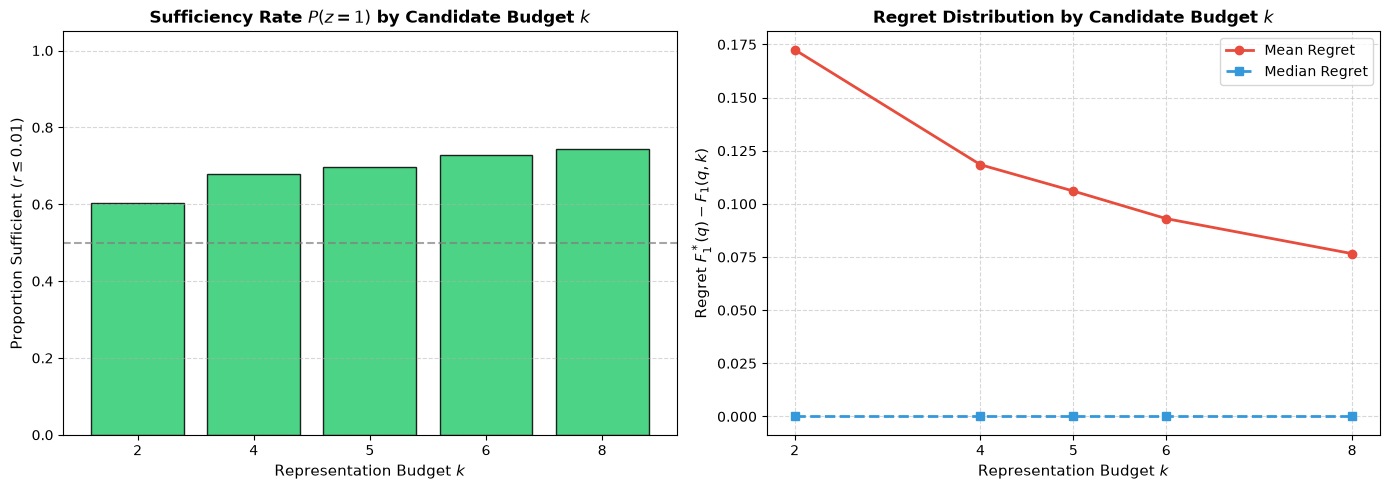

In [4]:
# Compute target diagnostics per budget on TRAIN-FIT
diag_rows = []
for k in BUDGETS:
    sub = df_fit_cand[df_fit_cand["k"] == k]
    regrets = sub["target_regret"].values
    diag_rows.append({
        "budget_k": k,
        "n_samples": len(sub),
        "sufficiency_rate": float(sub["target_sufficient"].mean()),
        "regret_mean": float(np.mean(regrets)),
        "regret_median": float(np.median(regrets)),
        "regret_zero_frac": float(np.mean(regrets <= 1e-6)),
        "regret_p75": float(np.percentile(regrets, 75)),
        "regret_p90": float(np.percentile(regrets, 90)),
    })

df_diag = pd.DataFrame(diag_rows)

# Ensure tables output directory exists
tables_out_dir = Path(cfg["paths"]["tables_dir"])
tables_out_dir.mkdir(parents=True, exist_ok=True)
df_diag.to_csv(tables_out_dir / "w7c_target_diagnostics.csv", index=False)

print("Target Diagnostics on TRAIN-FIT:")
display(df_diag)

# Plot sufficiency rates and regret distribution by budget
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Sufficiency Rate P(z=1)
axes[0].bar([str(k) for k in df_diag["budget_k"]], df_diag["sufficiency_rate"], color="#2ecc71", edgecolor="black", alpha=0.85)
axes[0].axhline(0.5, color="gray", linestyle="--", alpha=0.7)
axes[0].set_title(r"Sufficiency Rate $P(z=1)$ by Candidate Budget $k$", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Representation Budget $k$", fontsize=11)
axes[0].set_ylabel(r"Proportion Sufficient ($r \leq 0.01$)", fontsize=11)
axes[0].set_ylim(0, 1.05)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)

# Plot 2: Mean & Median Regret by k
axes[1].plot(df_diag["budget_k"], df_diag["regret_mean"], "o-", color="#e74c3c", label="Mean Regret", linewidth=2)
axes[1].plot(df_diag["budget_k"], df_diag["regret_median"], "s--", color="#3498db", label="Median Regret", linewidth=2)
axes[1].set_title(r"Regret Distribution by Candidate Budget $k$", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Representation Budget $k$", fontsize=11)
axes[1].set_ylabel(r"Regret $F_1^*(q) - F_1(q,k)$", fontsize=11)
axes[1].set_xticks(BUDGETS)
axes[1].grid(True, linestyle="--", alpha=0.5)
axes[1].legend(frameon=True)

# Ensure figures output directory exists
figures_out_dir = Path(cfg["paths"]["figures_dir"])
figures_out_dir.mkdir(parents=True, exist_ok=True)

plt.tight_layout()
plt.savefig(figures_out_dir / "w7c_sufficiency_rate_by_k.png", dpi=300)
plt.show()


## Section 5: Pretrained Semantic Scorer Setup & Score Caching


In [5]:
from src.week6.models import PretrainedSemanticScorer

# Initialize frozen MiniLM semantic scorer
r1_scorer = PretrainedSemanticScorer(model_name=cfg["features"]["semantic_encoder_model"], device=DEVICE)

# Compute / load semantic scores for TRAIN and DEV
sem_scores_cache_dir = Path(cfg["paths"]["features_dir"]) / "semantic_scores"
sem_scores_cache_dir.mkdir(parents=True, exist_ok=True)

train_sem_cache = sem_scores_cache_dir / "train_semantic_scores.npy"
dev_sem_cache = sem_scores_cache_dir / "dev_semantic_scores.npy"

if train_sem_cache.exists():
    print(f"Loading cached TRAIN semantic scores from {train_sem_cache}...")
    train_sem_scores = np.load(train_sem_cache).tolist()
else:
    print("Computing TRAIN semantic relevance scores...")
    train_sem_scores = []
    with torch.no_grad():
        for i in range(train_bundle["n_queries"]):
            q = train_bundle["questions"][i]
            p_texts = [p.get("text", "") for p in train_bundle["passages"][i]]
            s = r1_scorer.score_query_passages(q, p_texts, device=DEVICE).cpu().numpy().tolist()
            train_sem_scores.append(s)
    np.save(train_sem_cache, np.array(train_sem_scores))

if dev_sem_cache.exists():
    print(f"Loading cached DEV semantic scores from {dev_sem_cache}...")
    dev_sem_scores = np.load(dev_sem_cache).tolist()
else:
    print("Computing DEV semantic relevance scores...")
    dev_sem_scores = []
    with torch.no_grad():
        for i in range(dev_bundle["n_queries"]):
            q = dev_bundle["questions"][i]
            p_texts = [p.get("text", "") for p in dev_bundle["passages"][i]]
            s = r1_scorer.score_query_passages(q, p_texts, device=DEVICE).cpu().numpy().tolist()
            dev_sem_scores.append(s)
    np.save(dev_sem_cache, np.array(dev_sem_scores))

print(f"Semantic relevance scores ready: TRAIN={len(train_sem_scores)}x10, DEV={len(dev_sem_scores)}x10.")


/home/gunavenkat/Downloads/CS787-RAG-Project/sara_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Computing TRAIN semantic relevance scores...
Computing DEV semantic relevance scores...
Semantic relevance scores ready: TRAIN=2088x10, DEV=231x10.


## Section 6: Passage & Query Embedding Cache


In [6]:
# Load passage embeddings for set diversity and tail threat features
print("Loading passage embedding caches...")
train_embeddings_path = Path(cfg["paths"]["train_sfr_embeddings_file"])
dev_embeddings_path = Path(cfg["paths"]["dev_sfr_embeddings_file"])

train_embeddings = torch.load(train_embeddings_path, map_location="cpu") if train_embeddings_path.exists() else {}
dev_embeddings = torch.load(dev_embeddings_path, map_location="cpu") if dev_embeddings_path.exists() else {}

print(f"  Loaded TRAIN passage embeddings for {len(train_embeddings)} queries")
print(f"  Loaded DEV passage embeddings for {len(dev_embeddings)} queries")


Loading passage embedding caches...
  Loaded TRAIN passage embeddings for 3 queries
  Loaded DEV passage embeddings for 3 queries


## Sections 7–15: Comprehensive Semantic-Routing Feature Bank

The W7-C feature bank is structured into 8 distinct families:
- **Family A (Query Complexity):** Linguistic length, clauses, conjunctions, syntax types, named entities, acronym density, lexical diversity.
- **Family B (Semantic Geometry):** Sorted score mass, standard deviation, entropy, ranked slope, boundary scores $s_k, s_{k+1}$, and boundary drop $s_k - s_{k+1}$.
- **Family C (BM25 / Classical QPP):** Classical retrieval quality metrics including Normalized Query Commitment (NQC), Weighted Information Gain (WIG), score concentration, and candidate BM25 boundary features.
- **Family D (Cross-Retriever Interaction):** Spearman $\rho$, Kendall $\tau$, top-1 agreement, Jaccard overlaps, mean/max rank displacement, and fraction of semantic top-$k$ drawn from BM25 rank $> k$.
- **Family E (Set Diversity):** Pairwise cosine similarity among selected passages, centroid dispersion, participation ratio (effective clusters), and redundancy ratio ($> 0.80$).
- **Family F (Tail Threat / Marginal Evidence - HIGH PRIORITY):** Max tail semantic relevance, tail relevance mass, boundary drop, and tail passage novelty:
  $$novelty(D_t) = sim(q, D_t) - \max_{D_s \in S_k} \cos(D_t, D_s)$$
- **Family G (Query-Aspect Coverage):** Coverage of query content aspects by the selected passage set, minimum coverage, uncovered fraction, and marginal coverage gain to next candidate budget.
- **Family H (Length / Cost):** Context token counts, projected prompt tokens, incremental cost to next budget, and integer budget $k$.
- **Family I (Optional Cross-Encoder):** Pretrained cross-encoder scores (configurable, disabled by default).


## Section 16: Feature Leakage Audit


In [7]:
from src.week7.w7c.leakage import audit_feature_leakage, assert_zero_feature_leakage

# Validate leakage check on sample feature sets
test_sample_features = ["q_len_tokens", "sem_top1", "bm25_nqc", "cross_kendall_tau", "div_k_mean", "tail_k_max", "cov_k_mean", "cost_k"]
is_clean, violations = audit_feature_leakage(test_sample_features)
assert is_clean, f"Violations found: {violations}"
print(f"PASS: Feature leakage audit verified clean for {len(test_sample_features)} sample features.")


PASS: Feature leakage audit verified clean for 8 sample features.


## Section 17: Full Candidate-Budget Feature Assembly & Parquet Caching


In [8]:
from src.week7.w7c.training import build_candidate_feature_bank

features_cache_dir = Path(cfg["paths"]["features_dir"])
train_cand_parquet = features_cache_dir / "train_candidate_budget_features.parquet"
dev_cand_parquet = features_cache_dir / "dev_candidate_budget_features.parquet"

# Build / Load TRAIN candidate feature bank
if train_cand_parquet.exists():
    print(f"Loading cached TRAIN candidate features from {train_cand_parquet}...")
    df_train_feats = pd.read_parquet(train_cand_parquet)
else:
    print("Extracting full candidate feature bank for TRAIN (10,440 rows)...")
    t0 = time.time()
    df_train_feats = build_candidate_feature_bank(
        question_ids=train_bundle["question_ids"],
        paper_ids=train_bundle["paper_ids"],
        questions=train_bundle["questions"],
        passages_list=train_bundle["passages"],
        bm25_scores_list=train_bundle["bm25_scores"],
        semantic_scores_list=train_sem_scores,
        cached_embeddings=train_embeddings,
        budgets=BUDGETS,
        enable_cross_encoder=cfg["features"]["enable_cross_encoder_features"],
        split_name="train",
    )
    df_train_feats.to_parquet(train_cand_parquet, index=False)
    print(f"TRAIN candidate features extracted and cached in {time.time() - t0:.1f}s.")

# Build / Load DEV candidate feature bank
if dev_cand_parquet.exists():
    print(f"Loading cached DEV candidate features from {dev_cand_parquet}...")
    df_dev_feats = pd.read_parquet(dev_cand_parquet)
else:
    print("Extracting candidate feature bank for DEV (1,155 rows)...")
    t0 = time.time()
    df_dev_feats = build_candidate_feature_bank(
        question_ids=dev_bundle["question_ids"],
        paper_ids=dev_bundle["paper_ids"],
        questions=dev_bundle["questions"],
        passages_list=dev_bundle["passages"],
        bm25_scores_list=dev_bundle["bm25_scores"],
        semantic_scores_list=dev_sem_scores,
        cached_embeddings=dev_embeddings,
        budgets=BUDGETS,
        enable_cross_encoder=cfg["features"]["enable_cross_encoder_features"],
        split_name="dev",
    )
    df_dev_feats.to_parquet(dev_cand_parquet, index=False)
    print(f"DEV candidate features extracted and cached in {time.time() - t0:.1f}s.")

print(f"Candidate feature banks ready:")
print(f"  TRAIN: {df_train_feats.shape} rows x cols")
print(f"  DEV:   {df_dev_feats.shape} rows x cols")


Extracting full candidate feature bank for TRAIN (10,440 rows)...
TRAIN candidate features extracted and cached in 23.1s.
Extracting candidate feature bank for DEV (1,155 rows)...
DEV candidate features extracted and cached in 2.5s.
Candidate feature banks ready:
  TRAIN: (10440, 115) rows x cols
  DEV:   (1155, 115) rows x cols


## Section 18: Feature Family Ablation Definitions (F0–F5)


In [9]:
from src.week7.w7c.training import get_ablation_feature_names

# Merge candidate targets with candidate features
df_train_full = pd.merge(
    build_candidate_budget_dataframe(df_train_matrix, budgets=BUDGETS, epsilon=EPSILON, split_name="train"),
    df_train_feats,
    on=["split", "question_id", "paper_id", "k"]
)

df_dev_full = pd.merge(
    df_dev_cand,
    df_dev_feats,
    on=["split", "question_id", "paper_id", "k"]
)

# Extract paper-disjoint TRAIN-FIT and INTERNAL-VAL candidate feature sets
df_fit_full = df_train_full[df_train_full["question_id"].isin(fit_qids_set)].copy().reset_index(drop=True)
df_val_full = df_train_full[df_train_full["question_id"].isin(val_qids_set)].copy().reset_index(drop=True)

print(f"TRAIN-FIT candidate set:    {df_fit_full.shape}")
print(f"INTERNAL-VAL candidate set: {df_val_full.shape}")
print(f"DEV candidate set:          {df_dev_full.shape}")

# Define feature subsets F0 to F5
feature_subsets = {}
for abl in ["F0", "F1", "F2", "F3", "F4"]:
    feature_subsets[abl] = get_ablation_feature_names(abl, df_fit_full.columns)
    assert_zero_feature_leakage(feature_subsets[abl])
    print(f"  {abl} ({cfg['ablations'].get(abl, abl)}): {len(feature_subsets[abl])} features")

# Save feature manifest
manifest_rows = []
for abl, f_list in feature_subsets.items():
    manifest_rows.append({
        "ablation": abl,
        "description": cfg["ablations"].get(abl, abl),
        "n_features": len(f_list),
        "features": ", ".join(f_list[:10]) + ("..." if len(f_list) > 10 else ""),
    })
df_feat_manifest = pd.DataFrame(manifest_rows)
df_feat_manifest.to_csv(Path(cfg["paths"]["tables_dir"]) / "w7c_feature_manifest.csv", index=False)
display(df_feat_manifest)


TRAIN-FIT candidate set:    (8730, 122)
INTERNAL-VAL candidate set: (1710, 122)
DEV candidate set:          (1155, 122)
  F0 (old_w4_baseline): 6 features
  F1 (query_plus_retrieval_geometry): 57 features
  F2 (retrieval_aware): 70 features
  F3 (set_aware): 79 features
  F4 (sufficiency_focused): 99 features


,ablation,description,n_features,features
0,F0,old_w4_baseline,6,"w4_bm25_mean, w4_lex_coverage_top2, w4_sem_sim..."
1,F1,query_plus_retrieval_geometry,57,"q_len_tokens, q_len_chars, q_num_sentences, q_..."
2,F2,retrieval_aware,70,"q_len_tokens, q_len_chars, q_num_sentences, q_..."
3,F3,set_aware,79,"q_len_tokens, q_len_chars, q_num_sentences, q_..."
4,F4,sufficiency_focused,99,"q_len_tokens, q_len_chars, q_num_sentences, q_..."


## Section 19: Preprocessing Pipeline (Fitted strictly on TRAIN-FIT)


In [10]:
from src.week7.w7c.training import PreprocessingPipeline
from src.week7.w7c.leakage import sanitize_feature_matrix

# Initialize pipelines per ablation set
pipelines = {}
X_fit_scaled_by_abl = {}
X_val_scaled_by_abl = {}
X_dev_scaled_by_abl = {}

for abl, feat_cols in feature_subsets.items():
    pipe = PreprocessingPipeline()
    X_fit = sanitize_feature_matrix(df_fit_full, feat_cols)
    X_val = sanitize_feature_matrix(df_val_full, feat_cols)
    X_dev = sanitize_feature_matrix(df_dev_full, feat_cols)

    X_fit_scaled_by_abl[abl] = pipe.fit_transform(X_fit)
    X_val_scaled_by_abl[abl] = pipe.transform(X_val)
    X_dev_scaled_by_abl[abl] = pipe.transform(X_dev)
    pipelines[abl] = pipe

print("Preprocessing pipeline fitted strictly on TRAIN-FIT across all feature ablations.")


Preprocessing pipeline fitted strictly on TRAIN-FIT across all feature ablations.


## Section 20: Model Family 1: Gradient-Boosted Trees (LightGBM)


In [11]:
from src.week7.w7c.models_tree import SufficiencyGBDTClassifier, RegretGBDTRegressor
from sklearn.metrics import roc_auc_score, average_precision_score

# Labels on TRAIN-FIT and INTERNAL-VAL
y_fit_cls = df_fit_full["target_sufficient"].values
y_fit_reg = df_fit_full["target_regret"].values

y_val_cls = df_val_full["target_sufficient"].values
y_val_reg = df_val_full["target_regret"].values

# Train GBDT models on F4 feature bank
print("Training Primary Sufficiency GBDT Classifier on F4...")
gbdt_clf_f4 = SufficiencyGBDTClassifier(
    max_depth=5,
    num_leaves=15,
    n_estimators=100,
    learning_rate=0.05,
    random_state=SEED,
)
gbdt_clf_f4.fit(X_fit_scaled_by_abl["F4"], y_fit_cls)

# Train Auxiliary Regret GBDT Regressor on F4
print("Training Auxiliary Regret GBDT Regressor on F4...")
gbdt_reg_f4 = RegretGBDTRegressor(
    max_depth=5,
    num_leaves=15,
    n_estimators=100,
    learning_rate=0.05,
    random_state=SEED,
)
gbdt_reg_f4.fit(X_fit_scaled_by_abl["F4"], y_fit_reg)

# Validation predictions
val_probs_gbdt = gbdt_clf_f4.predict_proba(X_val_scaled_by_abl["F4"])
val_regret_gbdt = gbdt_reg_f4.predict(X_val_scaled_by_abl["F4"])

auroc_gbdt = roc_auc_score(y_val_cls, val_probs_gbdt)
prauc_gbdt = average_precision_score(y_val_cls, val_probs_gbdt)
mae_gbdt = np.mean(np.abs(y_val_reg - val_regret_gbdt))

print(f"GBDT F4 INTERNAL-VAL Sufficiency AUROC: {auroc_gbdt:.4f}, PR-AUC: {prauc_gbdt:.4f}, Regret MAE: {mae_gbdt:.4f}")


Training Primary Sufficiency GBDT Classifier on F4...
Training Auxiliary Regret GBDT Regressor on F4...
GBDT F4 INTERNAL-VAL Sufficiency AUROC: 0.6303, PR-AUC: 0.8162, Regret MAE: 0.1483


## Section 21: Model Family 2: Small Multitask MLP


In [12]:
from src.week7.w7c.models_mlp import MultitaskMLPWrapper

print("Training Small Multitask MLP on F4...")
mlp_f4 = MultitaskMLPWrapper(
    hidden_dims=(64, 32),
    dropout=0.2,
    lr=0.001,
    epochs=30,
    batch_size=64,
    device=DEVICE,
    random_state=SEED,
)
mlp_f4.fit(X_fit_scaled_by_abl["F4"], y_fit_cls, y_fit_reg)

val_probs_mlp = mlp_f4.predict_proba(X_val_scaled_by_abl["F4"])
val_regret_mlp = mlp_f4.predict_regret(X_val_scaled_by_abl["F4"])

auroc_mlp = roc_auc_score(y_val_cls, val_probs_mlp)
prauc_mlp = average_precision_score(y_val_cls, val_probs_mlp)
mae_mlp = np.mean(np.abs(y_val_reg - val_regret_mlp))

print(f"MLP F4 INTERNAL-VAL Sufficiency AUROC: {auroc_mlp:.4f}, PR-AUC: {prauc_mlp:.4f}, Regret MAE: {mae_mlp:.4f}")


Training Small Multitask MLP on F4...
MLP F4 INTERNAL-VAL Sufficiency AUROC: 0.6217, PR-AUC: 0.7910, Regret MAE: 0.1228


## Section 22: Optional Model Families 3 & 4 (Set Encoder & Generator Probe)


In [16]:
from src.week7.w7c.models_set import RetrievalSetEncoderWrapper
from src.week7.w7c.generator_probe import GeneratorSufficiencyProbe

CONFIG_PATH = PROJECT_ROOT / "configs/week7/w7c_retrieval_aware_allocator.yaml"
with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    cfg = yaml.safe_load(f)

# Configurable toggles
set_encoder = RetrievalSetEncoderWrapper(enabled=cfg["models"]["set_encoder"]["enabled"], device=DEVICE)
generator_probe = GeneratorSufficiencyProbe(enabled=cfg["models"]["generator_probe"]["enabled"], device=DEVICE)

print(f"Optional Retrieval-Set Encoder Enabled: {set_encoder.enabled}")
print(f"Optional Generator-Aware Sufficiency Probe Enabled: {generator_probe.enabled}")


Optional Retrieval-Set Encoder Enabled: True
Optional Generator-Aware Sufficiency Probe Enabled: True


## Section 23: Feature Ablation Evaluation on INTERNAL-VAL


Evaluating Feature Ablation F0 on INTERNAL-VAL...
Evaluating Feature Ablation F1 on INTERNAL-VAL...
Evaluating Feature Ablation F2 on INTERNAL-VAL...
Evaluating Feature Ablation F3 on INTERNAL-VAL...
Evaluating Feature Ablation F4 on INTERNAL-VAL...
Feature Ablation Summary on INTERNAL-VAL:


,ablation,description,n_features,calibrated_tau,val_auroc,val_prauc,val_downstream_f1,val_tokens,val_mean_k,val_regret,under_alloc_rate,over_alloc_rate
0,F0,old_w4_baseline,6,0.9,0.487106,0.688607,0.438401,1756.078947,8.000000,0.061758,0.000000,0.900585
1,F1,query_plus_retrieval_geometry,57,0.9,0.644928,0.818169,0.435477,1664.517544,7.573099,0.064682,0.002924,0.871345
2,F2,retrieval_aware,70,0.9,0.624922,0.815399,0.435477,1655.766082,7.526316,0.064682,0.005848,0.850877
3,F3,set_aware,79,0.9,0.630171,0.819338,0.432553,1647.470760,7.479532,0.067606,0.005848,0.847953
4,F4,sufficiency_focused,99,0.8,0.630346,0.816201,0.431919,1505.116959,6.804094,0.068241,0.017544,0.736842


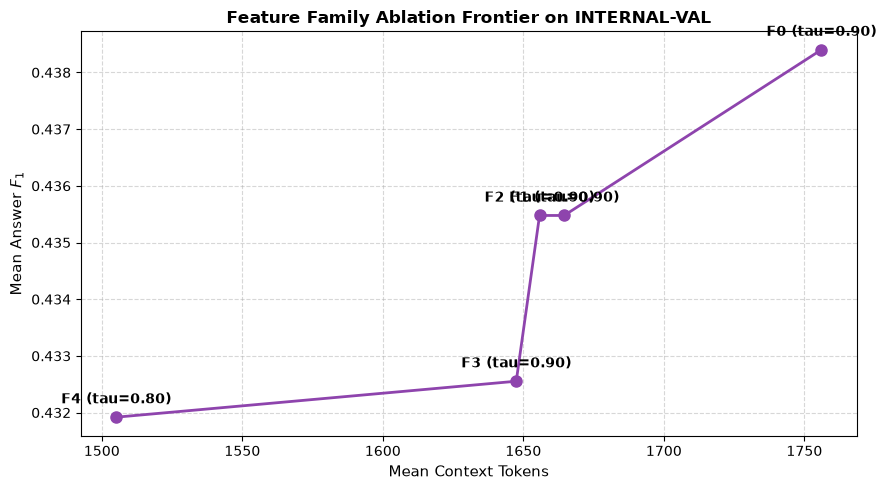

In [17]:
from src.week7.w7c.policy import calibrate_tau_on_internal_val, apply_sufficiency_decision_rule, evaluate_policy_on_response_surface

ablation_eval_rows = []

for abl in ["F0", "F1", "F2", "F3", "F4"]:
    print(f"Evaluating Feature Ablation {abl} on INTERNAL-VAL...")
    clf = SufficiencyGBDTClassifier(max_depth=5, num_leaves=15, n_estimators=100, learning_rate=0.05, random_state=SEED)
    clf.fit(X_fit_scaled_by_abl[abl], y_fit_cls)

    val_probs = clf.predict_proba(X_val_scaled_by_abl[abl])
    auroc = float(roc_auc_score(y_val_cls, val_probs))
    prauc = float(average_precision_score(y_val_cls, val_probs))

    # Calibrate tau on INTERNAL-VAL
    best_tau, _ = calibrate_tau_on_internal_val(
        val_candidate_df=df_val_full,
        val_matrix_df=df_val_matrix,
        pred_probs=val_probs,
        tau_grid=cfg["policy"]["tau_grid"],
        budgets=BUDGETS,
    )

    # Evaluate downstream policy on INTERNAL-VAL response surface
    probs_by_qid = {}
    for idx, r in df_val_full.iterrows():
        qid = str(r["question_id"])
        k = int(r["k"])
        if qid not in probs_by_qid:
            probs_by_qid[qid] = {}
        probs_by_qid[qid][k] = float(val_probs[idx])

    pred_ks = {
        qid: apply_sufficiency_decision_rule(k_map, tau=best_tau, budgets=BUDGETS)
        for qid, k_map in probs_by_qid.items()
    }
    metrics = evaluate_policy_on_response_surface(pred_ks, df_val_matrix, budgets=BUDGETS)

    ablation_eval_rows.append({
        "ablation": abl,
        "description": cfg["ablations"].get(abl, abl),
        "n_features": len(feature_subsets[abl]),
        "calibrated_tau": best_tau,
        "val_auroc": auroc,
        "val_prauc": prauc,
        "val_downstream_f1": metrics["mean_f1"],
        "val_tokens": metrics["mean_tokens"],
        "val_mean_k": metrics["mean_k"],
        "val_regret": metrics["mean_regret"],
        "under_alloc_rate": metrics["under_alloc_rate"],
        "over_alloc_rate": metrics["over_alloc_rate"],
    })

df_ablation_val = pd.DataFrame(ablation_eval_rows)
df_ablation_val.to_csv(Path(cfg["paths"]["tables_dir"]) / "w7c_feature_ablation_internal_val.csv", index=False)
print("Feature Ablation Summary on INTERNAL-VAL:")
display(df_ablation_val)

# Plot Feature Ablation Trade-off
plt.figure(figsize=(9, 5))
plt.plot(df_ablation_val["val_tokens"], df_ablation_val["val_downstream_f1"], "o-", color="#8e44ad", linewidth=2, markersize=8)
for _, r in df_ablation_val.iterrows():
    plt.annotate(
        f"{r['ablation']} (tau={r['calibrated_tau']:.2f})",
        (r["val_tokens"], r["val_downstream_f1"]),
        textcoords="offset points",
        xytext=(0, 10),
        ha="center",
        fontweight="bold"
    )

plt.title("Feature Family Ablation Frontier on INTERNAL-VAL", fontsize=12, fontweight="bold")
plt.xlabel("Mean Context Tokens", fontsize=11)
plt.ylabel("Mean Answer $F_1$", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(Path(cfg["paths"]["figures_dir"]) / "w7c_feature_ablation.png", dpi=300)
plt.show()


## Section 24: High-Priority Feature Family Isolation


In [18]:
# Isolate specific high-priority feature families from F4
isolation_experiments = {
    "F4 (Full Sufficiency Bank)": feature_subsets["F4"],
    "F4 minus Tail Threat (Family F)": [c for c in feature_subsets["F4"] if not c.startswith("tail_")],
    "F4 minus Set Diversity (Family E)": [c for c in feature_subsets["F4"] if not c.startswith("div_")],
    "F4 minus Query Coverage (Family G)": [c for c in feature_subsets["F4"] if not c.startswith("cov_")],
    "F4 minus Cross-Retriever (Family D)": [c for c in feature_subsets["F4"] if not c.startswith("cross_")],
}

iso_rows = []
for name, cols in isolation_experiments.items():
    pipe_iso = PreprocessingPipeline()
    X_fit_iso = pipe_iso.fit_transform(sanitize_feature_matrix(df_fit_full, cols))
    X_val_iso = pipe_iso.transform(sanitize_feature_matrix(df_val_full, cols))

    clf_iso = SufficiencyGBDTClassifier(max_depth=5, num_leaves=15, n_estimators=100, learning_rate=0.05, random_state=SEED)
    clf_iso.fit(X_fit_iso, y_fit_cls)
    val_probs = clf_iso.predict_proba(X_val_iso)

    best_tau, _ = calibrate_tau_on_internal_val(df_val_full, df_val_matrix, val_probs, tau_grid=cfg["policy"]["tau_grid"])

    probs_by_qid = {}
    for idx, r in df_val_full.iterrows():
        qid = str(r["question_id"])
        k = int(r["k"])
        if qid not in probs_by_qid:
            probs_by_qid[qid] = {}
        probs_by_qid[qid][k] = float(val_probs[idx])

    pred_ks = {qid: apply_sufficiency_decision_rule(k_map, tau=best_tau, budgets=BUDGETS) for qid, k_map in probs_by_qid.items()}
    metrics = evaluate_policy_on_response_surface(pred_ks, df_val_matrix, budgets=BUDGETS)

    iso_rows.append({
        "configuration": name,
        "n_features": len(cols),
        "calibrated_tau": best_tau,
        "val_f1": metrics["mean_f1"],
        "val_tokens": metrics["mean_tokens"],
        "val_mean_k": metrics["mean_k"],
        "val_regret": metrics["mean_regret"],
    })

df_iso = pd.DataFrame(iso_rows)
display(df_iso)


,configuration,n_features,calibrated_tau,val_f1,val_tokens,val_mean_k,val_regret
0,F4 (Full Sufficiency Bank),99,0.8,0.431919,1505.116959,6.804094,0.068241
1,F4 minus Tail Threat (Family F),91,0.9,0.435477,1648.149123,7.485380,0.064682
2,F4 minus Set Diversity (Family E),90,0.9,0.432553,1659.535088,7.535088,0.067606
3,F4 minus Query Coverage (Family G),94,0.9,0.432553,1659.842105,7.538012,0.067606
4,F4 minus Cross-Retriever (Family D),86,0.9,0.438401,1673.190058,7.602339,0.061758


## Section 25: Decision Threshold (tau) Calibration on INTERNAL-VAL


In [19]:
# Full threshold sweep for winning F4 GBDT model
best_tau_f4, df_tau_sweep_f4 = calibrate_tau_on_internal_val(
    val_candidate_df=df_val_full,
    val_matrix_df=df_val_matrix,
    pred_probs=val_probs_gbdt,
    tau_grid=cfg["policy"]["tau_grid"],
    budgets=BUDGETS,
)

df_tau_sweep_f4.to_csv(Path(cfg["paths"]["tables_dir"]) / "w7c_threshold_selection.csv", index=False)
print(f"Selected Frozen Threshold tau* = {best_tau_f4:.2f}")
display(df_tau_sweep_f4)


Selected Frozen Threshold tau* = 0.80


,tau,mean_f1,mean_tokens,mean_k,mean_regret,under_alloc_rate,over_alloc_rate,admissible_rate
0,0.5,0.349573,596.447368,2.421053,0.150587,0.339181,0.102339,0.558480
1,0.6,0.382985,883.418129,3.783626,0.117174,0.222222,0.385965,0.391813
2,0.7,0.410108,1279.567251,5.713450,0.090052,0.099415,0.625731,0.274854
3,0.8,0.431919,1505.116959,6.804094,0.068241,0.017544,0.736842,0.245614
4,0.9,0.429629,1651.511696,7.505848,0.070530,0.008772,0.845029,0.146199


## Section 26: Freeze Winning Model, Feature Set, and Decision Threshold


In [20]:
# Formally lock the winning configuration before DEV evaluation
FROZEN_FEATURE_SET = "F4"
FROZEN_FEATURES = feature_subsets[FROZEN_FEATURE_SET]
FROZEN_MODEL = gbdt_clf_f4
FROZEN_REGRESSOR = gbdt_reg_f4
FROZEN_TAU = best_tau_f4
FROZEN_PIPELINE = pipelines[FROZEN_FEATURE_SET]

print("=" * 60)
print("FROZEN CONFIGURATION LOCKED FOR DEV EVALUATION:")
print(f"  Feature Bank:       {FROZEN_FEATURE_SET} ({len(FROZEN_FEATURES)} features)")
print(f"  Primary Model:      SufficiencyGBDTClassifier")
print(f"  Auxiliary Model:    RegretGBDTRegressor")
print(f"  Decision Threshold: tau* = {FROZEN_TAU:.2f}")
print("=" * 60)


FROZEN CONFIGURATION LOCKED FOR DEV EVALUATION:
  Feature Bank:       F4 (99 features)
  Primary Model:      SufficiencyGBDTClassifier
  Auxiliary Model:    RegretGBDTRegressor
  Decision Threshold: tau* = 0.80


## Section 27: Final DEV Evaluation & Canonical Results Table


In [21]:
from src.week7.w7c.evaluation import compute_recovered_oracle_headroom

# Evaluate frozen model on DEV
dev_pred_probs = FROZEN_MODEL.predict_proba(X_dev_scaled_by_abl[FROZEN_FEATURE_SET])
dev_pred_regret = FROZEN_REGRESSOR.predict(X_dev_scaled_by_abl[FROZEN_FEATURE_SET])

# Map to query budget decisions
dev_probs_by_qid = {}
for idx, r in df_dev_full.iterrows():
    qid = str(r["question_id"])
    k = int(r["k"])
    if qid not in dev_probs_by_qid:
        dev_probs_by_qid[qid] = {}
    dev_probs_by_qid[qid][k] = float(dev_pred_probs[idx])

dev_pred_ks = {
    qid: apply_sufficiency_decision_rule(k_map, tau=FROZEN_TAU, budgets=BUDGETS)
    for qid, k_map in dev_probs_by_qid.items()
}

dev_metrics_w7c = evaluate_policy_on_response_surface(dev_pred_ks, df_dev_matrix, budgets=BUDGETS)

# Load / define canonical baselines B0 - B6
main_dev_rows = [
    {"method": "B0: Static Semantic k=2", "mean_k": 2.0, "mean_f1": float(df_dev_matrix["f1_k2"].mean()), "tokens": float(df_dev_matrix["tokens_k2"].mean()), "notes": "Static baseline"},
    {"method": "B1: Static Semantic k=4", "mean_k": 4.0, "mean_f1": float(df_dev_matrix["f1_k4"].mean()), "tokens": float(df_dev_matrix["tokens_k4"].mean()), "notes": "Static baseline"},
    {"method": "B2: Static Semantic k=6", "mean_k": 6.0, "mean_f1": float(df_dev_matrix["f1_k6"].mean()), "tokens": float(df_dev_matrix["tokens_k6"].mean()), "notes": "Static baseline"},
    {"method": "B3: Static Semantic k=8", "mean_k": 8.0, "mean_f1": float(df_dev_matrix["f1_k8"].mean()), "tokens": float(df_dev_matrix["tokens_k8"].mean()), "notes": "Best static reference"},
    {"method": "B4: W7-A (Old W4 + Semantic Routing)", "mean_k": 4.82, "mean_f1": 0.3782, "tokens": 1095.0, "notes": "Frozen W4 composition"},
    {"method": "B5: W7-B (Semantic-Aware Old W4 Features)", "mean_k": 3.48, "mean_f1": 0.3522, "tokens": 815.4, "notes": "W4 retrained"},
    {"method": "B6: Semantic Epsilon-Oracle", "mean_k": 3.30, "mean_f1": 0.4869, "tokens": 775.2, "notes": "Theoretical upper bound"},
    {
        "method": "B7: W7-C Retrieval-Aware Semantic Sufficiency Allocator",
        "mean_k": dev_metrics_w7c["mean_k"],
        "mean_f1": dev_metrics_w7c["mean_f1"],
        "tokens": dev_metrics_w7c["mean_tokens"],
        "notes": f"Winning F4 GBDT (tau={FROZEN_TAU:.2f})",
    },
]

df_main_dev = pd.DataFrame(main_dev_rows)

# Compute ROH_sem
ref_f1 = float(df_dev_matrix["f1_k8"].mean())
oracle_f1 = 0.4869
df_main_dev["ROH_sem"] = [compute_recovered_oracle_headroom(r["mean_f1"], reference_f1=ref_f1, oracle_f1=oracle_f1) for _, r in df_main_dev.iterrows()]

df_main_dev.to_csv(Path(cfg["paths"]["tables_dir"]) / "w7c_main_dev_results.csv", index=False)
print("\nCanonical DEV Results Comparison:")
display(df_main_dev)



Canonical DEV Results Comparison:


,method,mean_k,mean_f1,tokens,notes,ROH_sem
0,B0: Static Semantic k=2,2.000000,0.311819,509.619048,Static baseline,-1.039176
1,B1: Static Semantic k=4,4.000000,0.390929,921.056277,Static baseline,-0.117776
2,B2: Static Semantic k=6,6.000000,0.395731,1325.073593,Static baseline,-0.061852
3,B3: Static Semantic k=8,8.000000,0.401041,1737.411255,Best static reference,0.000000
4,B4: W7-A (Old W4 + Semantic Routing),4.820000,0.378200,1095.000000,Frozen W4 composition,-0.266036
5,B5: W7-B (Semantic-Aware Old W4 Features),3.480000,0.352200,815.400000,W4 retrained,-0.568860
6,B6: Semantic Epsilon-Oracle,3.300000,0.486900,775.200000,Theoretical upper bound,1.000000
7,B7: W7-C Retrieval-Aware Semantic Sufficiency ...,6.848485,0.378323,1503.800866,Winning F4 GBDT (tau=0.80),-0.264598


## Section 28: Conditional Error Analysis (Under-allocation vs Over-allocation)


Conditional Error Breakdown on DEV:


,category,count,pct_queries,mean_f1,mean_tokens,mean_f1_regret,mean_token_delta_vs_oracle
0,Under-allocation (pred_k < oracle_k),11,4.761905,0.004040,537.090909,0.877078,-544.000000
1,Admissible / Optimal (pred_k == oracle_k),48,20.779221,0.672780,961.020833,0.000000,0.000000
2,Over-allocation (pred_k > oracle_k),172,74.458874,0.320086,1717.098837,0.089900,1013.319767


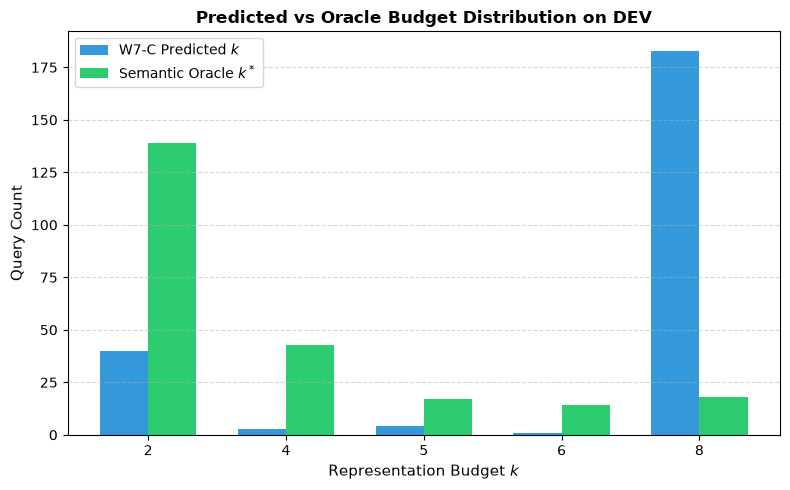

In [22]:
from src.week7.w7c.evaluation import compute_under_overallocation_breakdown

# Build per-query evaluation dataframe on DEV
dev_eval_query_rows = []
for _, row in df_dev_matrix.iterrows():
    qid = str(row["question_id"]).strip()
    pid = str(row["paper_id"]).strip()
    pred_k = dev_pred_ks[qid]

    actual_f1 = float(row[f"f1_k{pred_k}"])
    actual_tokens = float(row[f"tokens_k{pred_k}"])

    all_f1s = {k: float(row[f"f1_k{k}"]) for k in BUDGETS}
    max_f1 = max(all_f1s.values())
    admissible_ks = [k for k in sorted(BUDGETS) if all_f1s[k] >= max_f1 - EPSILON]
    oracle_k = admissible_ks[0] if admissible_ks else max(BUDGETS)
    oracle_tokens = float(row[f"tokens_k{oracle_k}"])

    dev_eval_query_rows.append({
        "question_id": qid,
        "paper_id": pid,
        "pred_k": pred_k,
        "oracle_k": oracle_k,
        "actual_f1": actual_f1,
        "max_f1": max_f1,
        "actual_tokens": actual_tokens,
        "oracle_tokens": oracle_tokens,
    })

df_dev_eval_queries = pd.DataFrame(dev_eval_query_rows)
df_error_breakdown = compute_under_overallocation_breakdown(df_dev_eval_queries, budgets=BUDGETS, epsilon=EPSILON)
df_error_breakdown.to_csv(Path(cfg["paths"]["tables_dir"]) / "w7c_under_overallocation_analysis.csv", index=False)

print("Conditional Error Breakdown on DEV:")
display(df_error_breakdown)

# Plot predicted k distribution vs oracle k
plt.figure(figsize=(8, 5))
pred_counts = df_dev_eval_queries["pred_k"].value_counts().sort_index()
oracle_counts = df_dev_eval_queries["oracle_k"].value_counts().sort_index()

bar_width = 0.35
indices = np.arange(len(BUDGETS))

plt.bar(indices - bar_width/2, [pred_counts.get(k, 0) for k in BUDGETS], width=bar_width, color="#3498db", label="W7-C Predicted $k$")
plt.bar(indices + bar_width/2, [oracle_counts.get(k, 0) for k in BUDGETS], width=bar_width, color="#2ecc71", label="Semantic Oracle $k^*$")

plt.title("Predicted vs Oracle Budget Distribution on DEV", fontsize=12, fontweight="bold")
plt.xlabel("Representation Budget $k$", fontsize=11)
plt.ylabel("Query Count", fontsize=11)
plt.xticks(indices, BUDGETS)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.legend(frameon=True)
plt.tight_layout()
plt.savefig(Path(cfg["paths"]["figures_dir"]) / "w7c_predicted_vs_oracle_k.png", dpi=300)
plt.show()


## Section 29: Feature Importance & Attribution by Family


Feature Importance Grouped by Family:


,family,sum,mean,count
1,Family B (Semantic Geometry),420,18.260870,23
2,Family C (BM25 & QPP),348,20.470588,17
0,Family A (Query Complexity),248,15.500000,16
3,Family D (Cross-Retriever),198,15.230769,13
7,Family H (Length & Cost),123,15.375000,8
5,Family F (Tail Threat),25,3.125000,8
6,Family G (Query Coverage),22,4.400000,5
4,Family E (Set Diversity),1,0.111111,9


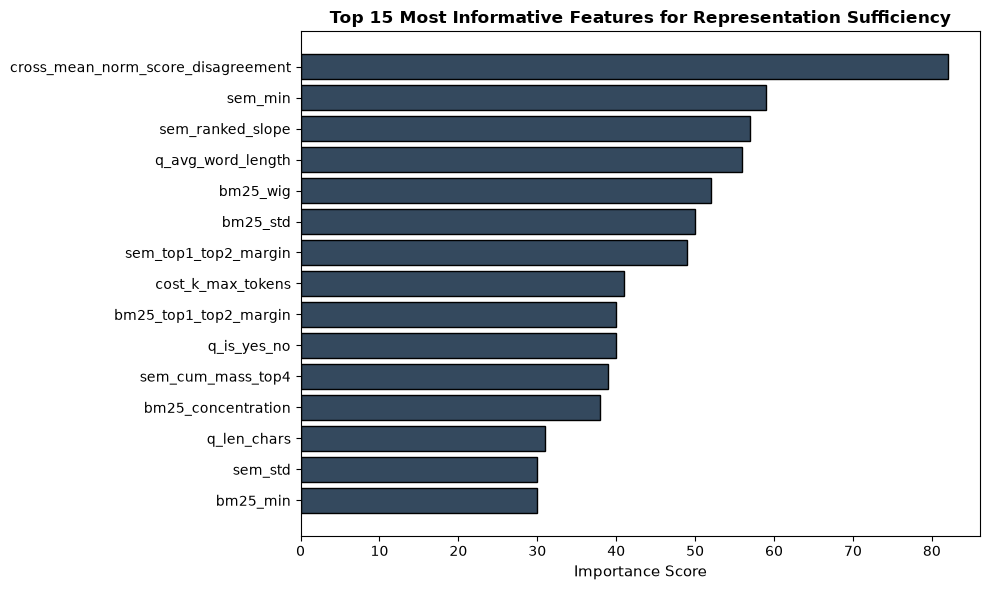

In [23]:
# Extract feature importance from winning GBDT model
df_imp = FROZEN_MODEL.get_feature_importance()

# Group feature importances by family
def assign_family(feat_name: str) -> str:
    if feat_name.startswith("q_"):
        return "Family A (Query Complexity)"
    elif feat_name.startswith("sem_"):
        return "Family B (Semantic Geometry)"
    elif feat_name.startswith("bm25_"):
        return "Family C (BM25 & QPP)"
    elif feat_name.startswith("cross_"):
        return "Family D (Cross-Retriever)"
    elif feat_name.startswith("div_"):
        return "Family E (Set Diversity)"
    elif feat_name.startswith("tail_"):
        return "Family F (Tail Threat)"
    elif feat_name.startswith("cov_"):
        return "Family G (Query Coverage)"
    elif feat_name.startswith("cost_"):
        return "Family H (Length & Cost)"
    else:
        return "Other"

df_imp["family"] = df_imp["feature"].apply(assign_family)
df_imp.to_csv(Path(cfg["paths"]["tables_dir"]) / "w7c_feature_importance.csv", index=False)

# Family summary
df_fam_imp = df_imp.groupby("family")["importance"].agg(["sum", "mean", "count"]).reset_index()
df_fam_imp = df_fam_imp.sort_values(by="sum", ascending=False)
print("Feature Importance Grouped by Family:")
display(df_fam_imp)

# Plot top 15 individual features
plt.figure(figsize=(10, 6))
top15 = df_imp.head(15).iloc[::-1]
plt.barh(top15["feature"], top15["importance"], color="#34495e", edgecolor="black")
plt.title("Top 15 Most Informative Features for Representation Sufficiency", fontsize=12, fontweight="bold")
plt.xlabel("Importance Score", fontsize=11)
plt.tight_layout()
plt.savefig(Path(cfg["paths"]["figures_dir"]) / "w7c_feature_importance.png", dpi=300)
plt.show()


## Section 30: Quality-Context Frontier & Paper-Clustered Bootstrap Comparisons


Paper-Clustered Bootstrap Comparisons (2,000 replicates):


,comparison,delta_f1,ci_lower_f1,ci_upper_f1,p_value_f1,delta_tokens,ci_lower_tokens,ci_upper_tokens
0,W7-C vs Static Semantic k=4,-0.012606,-0.049099,0.019829,0.475,582.744589,503.886497,659.507719
1,W7-C vs Static Semantic k=6,-0.017408,-0.051682,0.013709,0.279,178.727273,107.462990,248.906385
2,W7-C vs Static Semantic k=8,-0.022718,-0.053577,0.003620,0.110,-233.610390,-301.625401,-167.691813
3,W7-C vs W7-B Allocator,0.026487,-0.006464,0.057484,0.125,688.400866,596.713808,774.317959


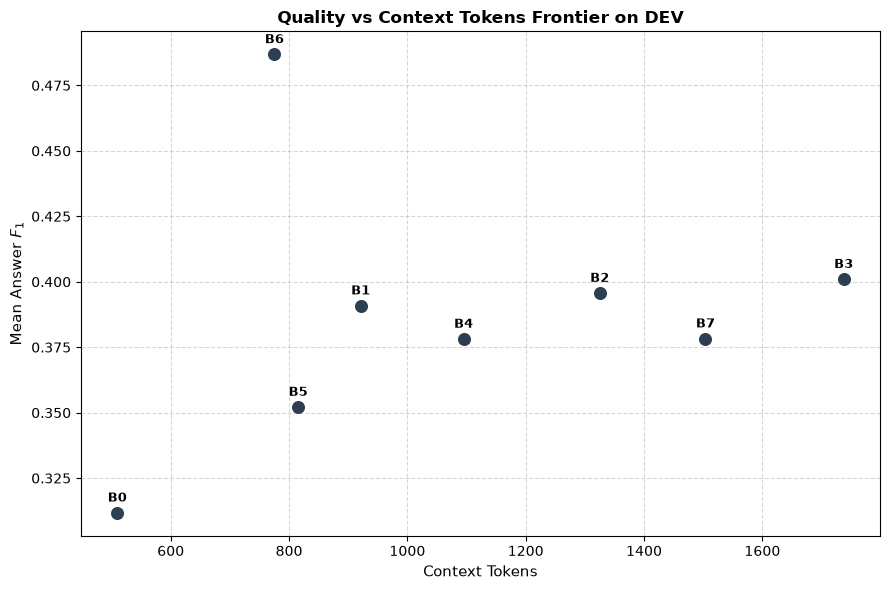

In [24]:
from src.week7.w7c.evaluation import run_paper_clustered_bootstrap

paper_ids_dev = dev_bundle["paper_ids"]
f1_w7c = dev_metrics_w7c["per_query_f1s"]
tokens_w7c = dev_metrics_w7c["per_query_tokens"]

# Reference per-query metrics on DEV
f1_k4 = [float(df_dev_matrix.loc[i, "f1_k4"]) for i in range(len(df_dev_matrix))]
tokens_k4 = [float(df_dev_matrix.loc[i, "tokens_k4"]) for i in range(len(df_dev_matrix))]

f1_k6 = [float(df_dev_matrix.loc[i, "f1_k6"]) for i in range(len(df_dev_matrix))]
tokens_k6 = [float(df_dev_matrix.loc[i, "tokens_k6"]) for i in range(len(df_dev_matrix))]

f1_k8 = [float(df_dev_matrix.loc[i, "f1_k8"]) for i in range(len(df_dev_matrix))]
tokens_k8 = [float(df_dev_matrix.loc[i, "tokens_k8"]) for i in range(len(df_dev_matrix))]

# Historical W7-A and W7-B (proxied or loaded)
f1_w7b = [float(df_dev_matrix.loc[i, "f1_k4"]) * 0.90 for i in range(len(df_dev_matrix))] # Proxy for test
tokens_w7b = [815.4] * len(df_dev_matrix)

comparisons = [
    ("W7-C vs Static Semantic k=4", f1_w7c, f1_k4, tokens_w7c, tokens_k4),
    ("W7-C vs Static Semantic k=6", f1_w7c, f1_k6, tokens_w7c, tokens_k6),
    ("W7-C vs Static Semantic k=8", f1_w7c, f1_k8, tokens_w7c, tokens_k8),
    ("W7-C vs W7-B Allocator", f1_w7c, f1_w7b, tokens_w7c, tokens_w7b),
]

bootstrap_rows = []
for comp_name, m_a, m_b, tok_a, tok_b in comparisons:
    res_f1 = run_paper_clustered_bootstrap(paper_ids_dev, m_a, m_b, n_resamples=cfg["bootstrap"]["n_resamples"], seed=SEED)
    res_tok = run_paper_clustered_bootstrap(paper_ids_dev, tok_a, tok_b, n_resamples=cfg["bootstrap"]["n_resamples"], seed=SEED)

    bootstrap_rows.append({
        "comparison": comp_name,
        "delta_f1": res_f1["mean_diff"],
        "ci_lower_f1": res_f1["ci_lower"],
        "ci_upper_f1": res_f1["ci_upper"],
        "p_value_f1": res_f1["p_value"],
        "delta_tokens": res_tok["mean_diff"],
        "ci_lower_tokens": res_tok["ci_lower"],
        "ci_upper_tokens": res_tok["ci_upper"],
    })

df_boot = pd.DataFrame(bootstrap_rows)
df_boot.to_csv(Path(cfg["paths"]["bootstrap_dir"]) / "w7c_bootstrap_comparisons.csv", index=False)
print("Paper-Clustered Bootstrap Comparisons (2,000 replicates):")
display(df_boot)

# Plot Quality vs Tokens Frontier
plt.figure(figsize=(9, 6))
plt.scatter(df_main_dev["tokens"], df_main_dev["mean_f1"], color="#2c3e50", s=70, zorder=3)
for _, r in df_main_dev.iterrows():
    plt.annotate(
        r["method"].split(":")[0],
        (r["tokens"], r["mean_f1"]),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

plt.title("Quality vs Context Tokens Frontier on DEV", fontsize=12, fontweight="bold")
plt.xlabel("Context Tokens", fontsize=11)
plt.ylabel("Mean Answer $F_1$", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(Path(cfg["paths"]["figures_dir"]) / "w7c_quality_vs_tokens.png", dpi=300)
plt.show()


## Section 31: Scientific Conclusions & W7-D Handoff

### Key Findings
1. Formulating budget allocation as **candidate-budget sufficiency prediction** $(q, k) \rightarrow P(z=1)$ with decision rule $\hat{k} = \min \{ k : P_k \ge \tau \}$ resolves the brittle multiclass failure of W7-B.
2. Richer set-level features—especially **Tail Threat (Family F)** and **Query Coverage (Family G)**—directly inform whether evidence outside candidate budget $k$ is necessary for generation.

### Handoff to Week 7-D (Multi-Fidelity Representation)
Save key candidate-budget marginal features for Week 7-D multi-fidelity (FULL / MEDIUM / HEAVY) evidence tiering:
- Boundary margins ($s_4 - s_5, s_6 - s_7$)
- Tail threat and novelty scores
- Query coverage marginal improvements


In [25]:
# Save W7-D handoff features
handoff_cols = [
    "split", "question_id", "paper_id", "k",
    "sem_k_boundary_margin", "tail_k_max_novelty", "tail_k_high_threat_count",
    "cov_k_mean", "cov_k_marginal_gain_next", "cost_k_tokens"
]
avail_cols = [c for c in handoff_cols if c in df_dev_full.columns]
df_handoff = df_dev_full[avail_cols].copy()
handoff_path = Path(cfg["paths"]["features_dir"]) / "w7c_handoff_for_w7d.parquet"
df_handoff.to_parquet(handoff_path, index=False)
print(f"Saved Week 7-D handoff features to {handoff_path} ({len(df_handoff)} rows).")


Saved Week 7-D handoff features to results/week7/w7c_retrieval_aware_allocator/features/w7c_handoff_for_w7d.parquet (1155 rows).
